## Импорты и настройки


In [1]:
import math
import random
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 13
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"Device: {DEVICE}")


Device: cpu


## Этап 1. Сеть Элмана для динамического образа


In [2]:
def variant_signal(k: np.ndarray) -> np.ndarray:
    return np.sin(2 * k**2 - 6 * k + 3)


def make_elman_sequence(repeats: list[int]) -> tuple[np.ndarray, np.ndarray]:
    step = 0.025
    k1 = np.arange(0.0, 1.0 + step / 2, step)
    k2 = np.arange(-0.02, 2.36 + step / 2, step)

    p1 = np.sin(4 * math.pi * k1)
    p2 = variant_signal(k2)
    t1 = -np.ones_like(p1)
    t2 = np.ones_like(p2)

    parts_x = []
    parts_y = []
    for count in repeats:
        parts_x.extend([p1] * count)
        parts_x.append(p2)
        parts_y.extend([t1] * count)
        parts_y.append(t2)

    return np.concatenate(parts_x), np.concatenate(parts_y)


In [3]:
class ElmanNet(nn.Module):
    def __init__(self, hidden_size: int = 8):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=hidden_size, nonlinearity="tanh", batch_first=True)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        hidden, _ = self.rnn(x)
        return torch.tanh(self.output(hidden))


@dataclass
class ElmanResult:
    loss: float
    correct: int
    total: int
    prediction: np.ndarray


def train_elman(x_np: np.ndarray, y_np: np.ndarray, epochs: int = 1000) -> tuple[ElmanNet, ElmanResult]:
    model = ElmanNet(hidden_size=8).to(DEVICE)
    x = torch.tensor(x_np, dtype=torch.float32, device=DEVICE).view(1, -1, 1)
    y = torch.tensor(y_np, dtype=torch.float32, device=DEVICE).view(1, -1, 1)

    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.MSELoss()
    best_loss = float("inf")

    for _ in range(epochs):
        optimizer.zero_grad()
        pred = model(x)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()
        best_loss = min(best_loss, float(loss.item()))
        if loss.item() < 1e-5:
            break

    with torch.no_grad():
        prediction = model(x).squeeze().detach().cpu().numpy()
    classes = np.where(prediction >= 0, 1, -1)
    correct = int((classes == y_np).sum())
    return model, ElmanResult(best_loss, correct, len(y_np), prediction)


Elman train loss: 0.182296
Correct points: 698/821


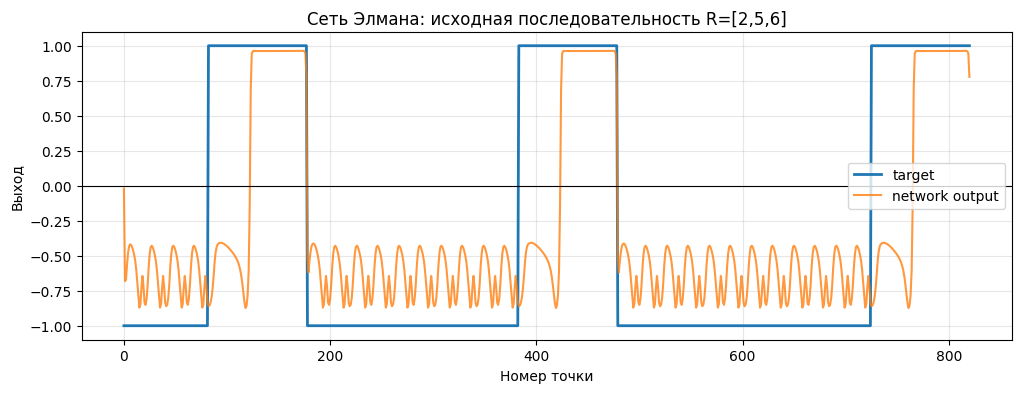

In [4]:
x_train, y_train = make_elman_sequence([2, 5, 6])
elman_model, train_result = train_elman(x_train, y_train)

print(f"Elman train loss: {train_result.loss:.6f}")
print(f"Correct points: {train_result.correct}/{train_result.total}")

plt.figure(figsize=(12, 4))
plt.plot(y_train, label="target", linewidth=2)
plt.plot(train_result.prediction, label="network output", alpha=0.8)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Сеть Элмана: исходная последовательность R=[2,5,6]")
plt.xlabel("Номер точки")
plt.ylabel("Выход")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Changed sequence R=[2,4,6]: 657/780 correct


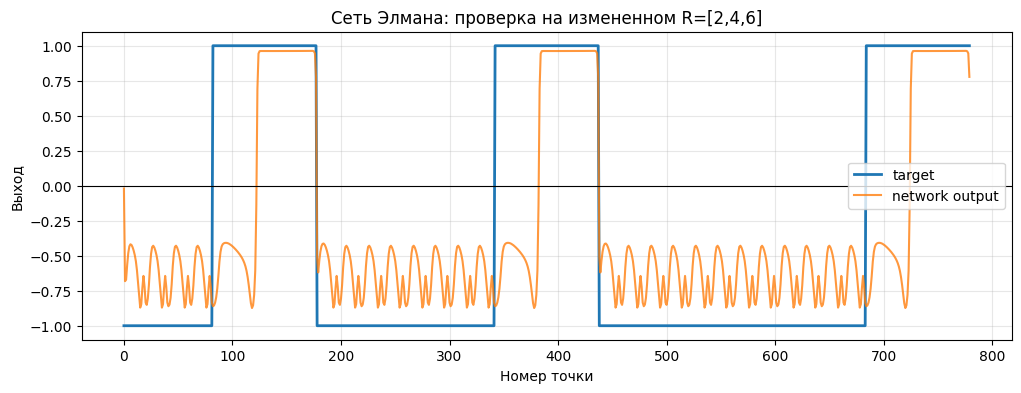

In [5]:
x_changed, y_changed = make_elman_sequence([2, 4, 6])
with torch.no_grad():
    changed_tensor = torch.tensor(x_changed, dtype=torch.float32, device=DEVICE).view(1, -1, 1)
    changed_prediction = elman_model(changed_tensor).squeeze().cpu().numpy()

changed_classes = np.where(changed_prediction >= 0, 1, -1)
changed_correct = int((changed_classes == y_changed).sum())

print(f"Changed sequence R=[2,4,6]: {changed_correct}/{len(y_changed)} correct")

plt.figure(figsize=(12, 4))
plt.plot(y_changed, label="target", linewidth=2)
plt.plot(changed_prediction, label="network output", alpha=0.8)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Сеть Элмана: проверка на измененном R=[2,4,6]")
plt.xlabel("Номер точки")
plt.ylabel("Выход")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Этап 2. Сеть Хопфилда для статических образов


In [6]:
DIGITS = {
    0: [
        "0111111110",
        "1111111111",
        "1100000011",
        "1100000011",
        "1100000011",
        "1100000011",
        "1100000011",
        "1100000011",
        "1100000011",
        "1100000011",
        "1111111111",
        "0111111110",
    ],
    1: [
        "0000110000",
        "0001110000",
        "0011110000",
        "0000110000",
        "0000110000",
        "0000110000",
        "0000110000",
        "0000110000",
        "0000110000",
        "0000110000",
        "0011111100",
        "0011111100",
    ],
    4: [
        "1100001100",
        "1100001100",
        "1100001100",
        "1100001100",
        "1111111111",
        "1111111111",
        "0000001100",
        "0000001100",
        "0000001100",
        "0000001100",
        "0000001100",
        "0000001100",
    ],
}


def digit_to_pattern(digit: int) -> np.ndarray:
    image = np.array([[int(ch) for ch in row] for row in DIGITS[digit]], dtype=np.float32)
    return np.where(image > 0, 1.0, -1.0)


def add_noise(pattern: np.ndarray, amount: float, seed: int) -> np.ndarray:
    rng = np.random.default_rng(seed)
    noisy = pattern.copy()
    mask = rng.random(pattern.shape) < amount
    noisy[mask] *= -1
    return noisy


def show_pattern(ax: plt.Axes, pattern: np.ndarray, title: str) -> None:
    shown = np.where(pattern > 0, 0, 1)
    ax.imshow(shown, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

In [7]:
def train_hopfield(patterns: list[np.ndarray]) -> np.ndarray:
    vectors = [p.reshape(-1) for p in patterns]
    size = vectors[0].size
    weights = np.zeros((size, size), dtype=np.float32)
    for vector in vectors:
        weights += np.outer(vector, vector)
    np.fill_diagonal(weights, 0.0)
    return weights / size


def run_hopfield(weights: np.ndarray, pattern: np.ndarray, iterations: int = 600) -> np.ndarray:
    state = pattern.reshape(-1).copy()
    for _ in range(iterations):
        updated = np.sign(weights @ state)
        updated[updated == 0] = state[updated == 0]
        if np.array_equal(updated, state):
            break
        state = updated
    return state.reshape(pattern.shape)

Hopfield 0 clean: closest digit=0, distances=[0, 69, 70]
Hopfield 1 noise 20%: closest digit=1, distances=[69, 0, 67]
Hopfield 4 noise 30%: closest digit=4, distances=[70, 67, 0]


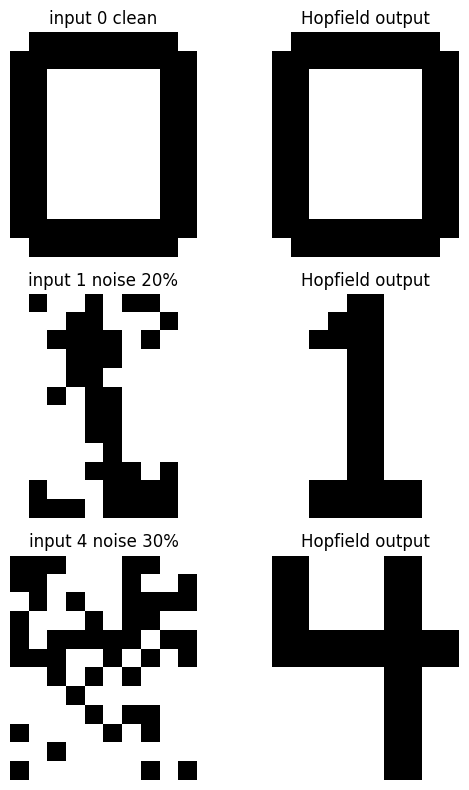

In [8]:
digits = [0, 1, 4]
patterns = [digit_to_pattern(digit) for digit in digits]
hopfield_weights = train_hopfield(patterns)

noisy_1 = add_noise(patterns[1], 0.20, seed=31)
noisy_4 = add_noise(patterns[2], 0.30, seed=41)
hopfield_inputs = [(patterns[0], "0 clean"), (noisy_1, "1 noise 20%"), (noisy_4, "4 noise 30%")]

fig, axes = plt.subplots(3, 2, figsize=(6, 8))
for row, (pattern, name) in enumerate(hopfield_inputs):
    recognized = run_hopfield(hopfield_weights, pattern)
    show_pattern(axes[row, 0], pattern, f"input {name}")
    show_pattern(axes[row, 1], recognized, "Hopfield output")
    distances = [int((recognized.reshape(-1) != p.reshape(-1)).sum()) for p in patterns]
    print(f"Hopfield {name}: closest digit={digits[int(np.argmin(distances))]}, distances={distances}")

plt.tight_layout()
plt.show()

## Этап 3. Сеть Хэмминга


In [9]:
def hamming_classify(patterns: list[np.ndarray], pattern: np.ndarray, iterations: int = 600) -> tuple[np.ndarray, int]:
    vectors = np.stack([p.reshape(-1) for p in patterns])
    q = len(patterns)
    r = pattern.size
    eps = 1.0 / (q - 1)

    activation = (vectors @ pattern.reshape(-1) + r).astype(np.float32)
    lateral = np.full((q, q), -eps, dtype=np.float32)
    np.fill_diagonal(lateral, 1.0)

    for _ in range(iterations):
        new_activation = np.maximum(lateral @ activation, 0.0)
        if np.allclose(new_activation, activation):
            break
        activation = new_activation

    return activation, int(np.argmax(activation))

Hamming 0 clean: activation=[139.0, 0.0, 0.0], digit=0
Hamming 1 noise 20%: activation=[0.0, 86.0, 0.0], digit=1
Hamming 4 noise 30%: activation=[0.0, 0.0, 73.0], digit=4


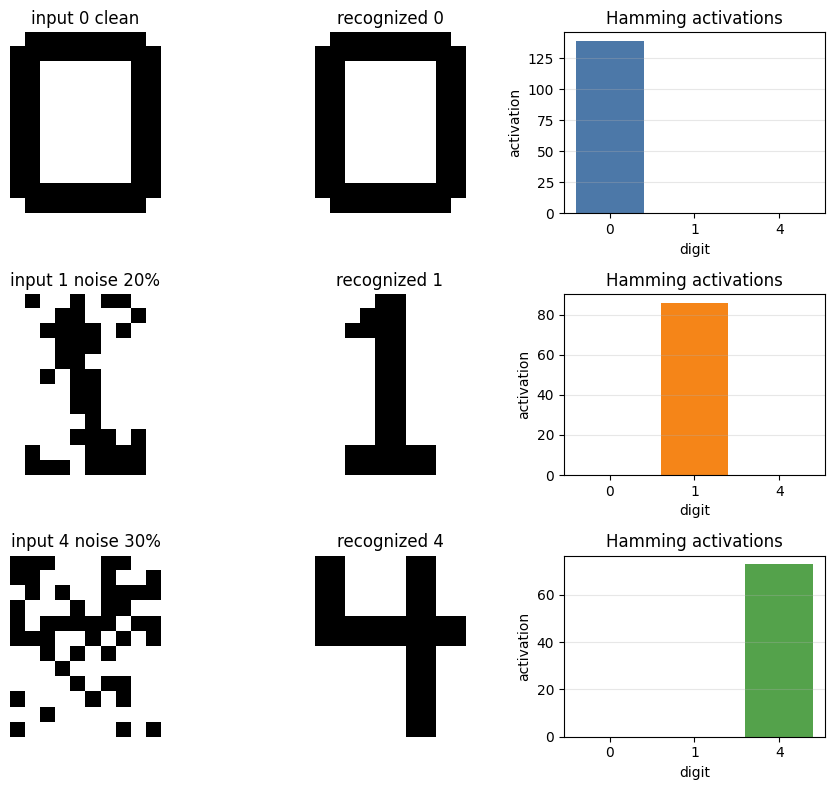

In [10]:
hamming_results = []
for pattern, name in hopfield_inputs:
    activation, index = hamming_classify(patterns, pattern)
    recognized_pattern = patterns[index]
    hamming_results.append((pattern, name, activation, index, recognized_pattern))
    print(f"Hamming {name}: activation={np.round(activation, 2).tolist()}, digit={digits[index]}")

fig, axes = plt.subplots(len(hamming_results), 3, figsize=(9, 8))
for row, (pattern, name, activation, index, recognized_pattern) in enumerate(hamming_results):
    show_pattern(axes[row, 0], pattern, f"input {name}")
    show_pattern(axes[row, 1], recognized_pattern, f"recognized {digits[index]}")

    axes[row, 2].bar([str(digit) for digit in digits], activation, color=["#4c78a8", "#f58518", "#54a24b"])
    axes[row, 2].set_title("Hamming activations")
    axes[row, 2].set_xlabel("digit")
    axes[row, 2].set_ylabel("activation")
    axes[row, 2].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
